Sujet 12: Prix de pétrole WTI   
Un modèle d’apprentissage automatique entraîné sur l’historique des prix du WTI permet-il de prévoir le prix à 5 jours ouvrés mieux qu’une simple persistance (le prix de demain = le prix d’aujourd’hui) ?

In [24]:
!pip install pandas numpy matplotlib scikit-learn

In [25]:
# Importation des bibliothèques nécessaires

import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Modèle de Machine Learning
from sklearn.ensemble import RandomForestRegressor

# Validation chronologique
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV

# Métriques d'évaluation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Paramètres généraux
GRAINE = 42
HORIZON = 5

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [26]:
# URL de téléchargement des données WTI

url = "https://fred.stlouisfed.org/graph/fredgraph.csv?id=DCOILWTICO"

# Chargement des données
df = pd.read_csv(url)

# Renommer les colonnes
df.columns = ["Date", "WTI"]

# Conversion des types
df["Date"] = pd.to_datetime(df["Date"])
df["WTI"] = pd.to_numeric(df["WTI"], errors="coerce")

# Nettoyage initial
df = df.dropna(subset=["WTI"])
df = df.drop_duplicates(subset=["Date"])

# Trier les données chronologiquement
df = df.sort_values("Date")

# Utiliser la date comme index
df = df.set_index("Date")

print("Données chargées avec succès.")

Données chargées avec succès.


In [27]:
# Afficher les cinq premières observations
print("Les cinq premières observations :")
display(df.head())

# Afficher les cinq dernières observations
print("Les cinq dernières observations :")
display(df.tail())

# Dimensions du dataset
print("Dimensions :", df.shape)

# Informations générales
print("\nInformations sur les données :")
df.info()

# Statistiques descriptives
print("\nStatistiques descriptives :")
display(df.describe())

# Période étudiée
print("\nDate de début :", df.index.min())
print("Date de fin :", df.index.max())

Les cinq premières observations :


,WTI
Date,
1986-01-02,25.56
1986-01-03,26.00
1986-01-06,26.53
1986-01-07,25.85
1986-01-08,25.87


Les cinq dernières observations :


,WTI
Date,
2026-11-05,94.05
2026-11-06,94.37
2026-11-09,90.40
2026-11-10,89.62
2026-11-11,89.62


Dimensions : (9543, 1)

Informations sur les données :
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 9543 entries, 1986-01-02 to 2026-11-11
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   WTI     9543 non-null   float64
dtypes: float64(1)
memory usage: 149.1 KB

Statistiques descriptives :


,WTI
count,9543.000000
mean,50.137597
std,29.931721
min,-36.980000
25%,20.510000
50%,47.270000
75%,73.490000
max,145.310000



Date de début : 1986-01-02 00:00:00
Date de fin : 2026-11-11 00:00:00


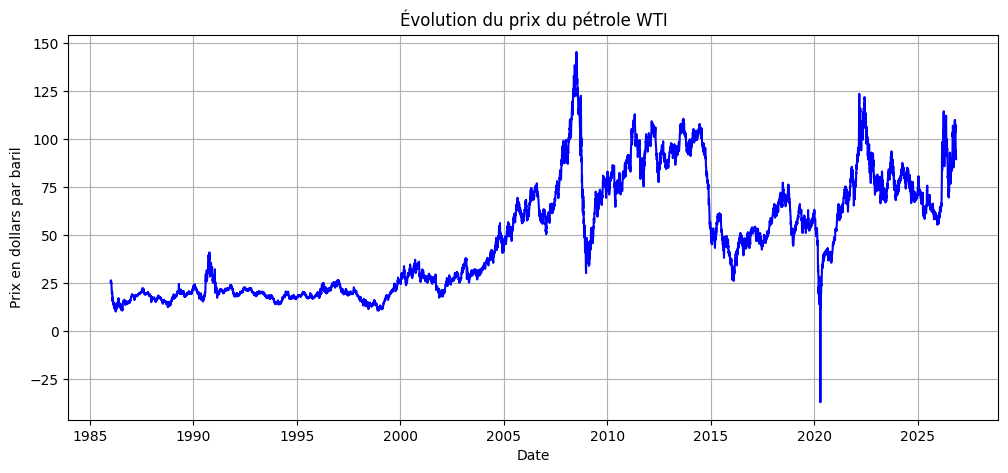

In [28]:
plt.figure(figsize=(12, 5))

plt.plot(df.index, df["WTI"], color="blue")

plt.title("Évolution du prix du pétrole WTI")
plt.xlabel("Date")
plt.ylabel("Prix en dollars par baril")

plt.grid(True)
plt.show()

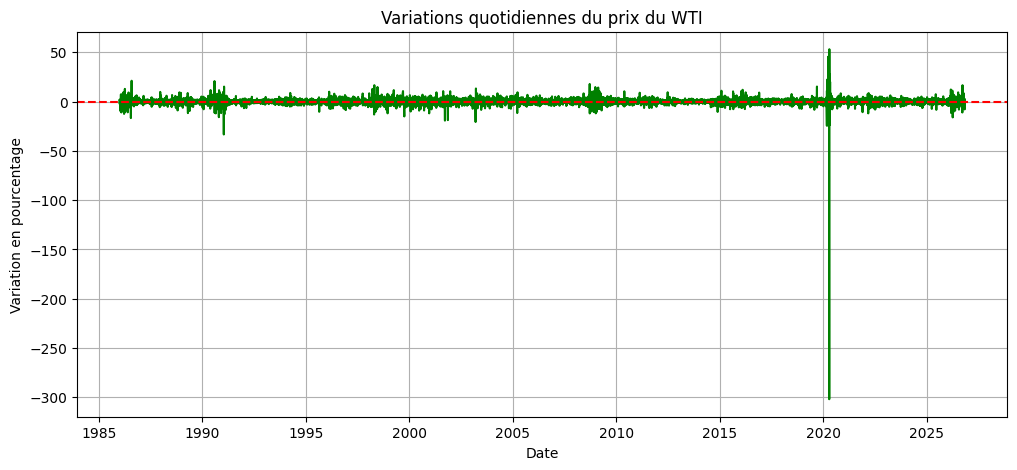

In [29]:
# Calcul des rendements quotidiens en pourcentage

df["Rendement"] = df["WTI"].pct_change() * 100

plt.figure(figsize=(12, 5))

plt.plot(df.index, df["Rendement"], color="green")

plt.title("Variations quotidiennes du prix du WTI")
plt.xlabel("Date")
plt.ylabel("Variation en pourcentage")

plt.axhline(0, color="red", linestyle="--")
plt.grid(True)

plt.show()

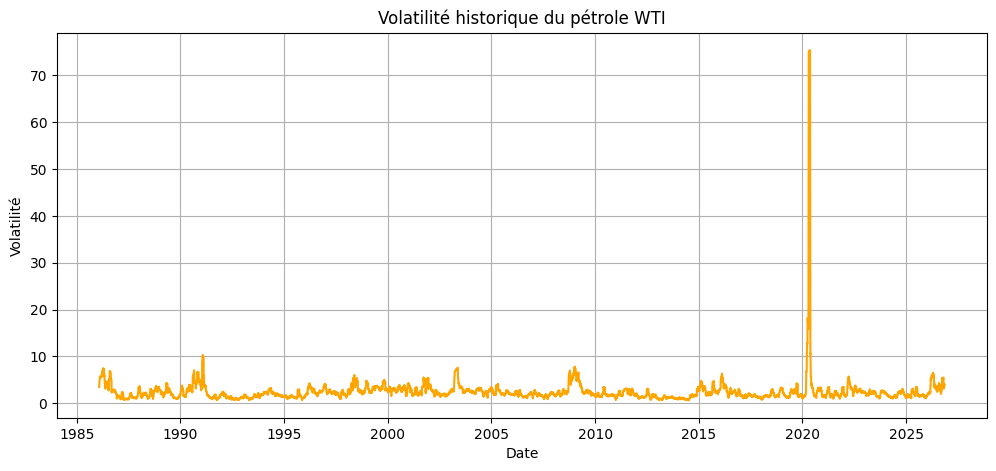

In [30]:
# Calcul de la volatilité sur 20 observations

df["Volatilite"] = (
    df["Rendement"].rolling(window=20).std()
)

plt.figure(figsize=(12, 5))

plt.plot(
    df.index,
    df["Volatilite"],
    color="orange"
)

plt.title("Volatilité historique du pétrole WTI")
plt.xlabel("Date")
plt.ylabel("Volatilité")

plt.grid(True)
plt.show()

In [31]:
# Vérification des valeurs manquantes
print("Valeurs manquantes :")
print(df.isnull().sum())

# Vérification des doublons
print("\nNombre de doublons :")
print(df.index.duplicated().sum())

# Statistiques pour identifier les valeurs extrêmes
print("\nStatistiques du prix WTI :")
print(df["WTI"].describe())

# Vérification des valeurs négatives
print("\nNombre de prix négatifs :")
print((df["WTI"] < 0).sum())

Valeurs manquantes :
WTI            0
Rendement      1
Volatilite    20
dtype: int64

Nombre de doublons :
0

Statistiques du prix WTI :
count    9543.000000
mean       50.137597
std        29.931721
min       -36.980000
25%        20.510000
50%        47.270000
75%        73.490000
max       145.310000
Name: WTI, dtype: float64

Nombre de prix négatifs :
1


In [32]:
# Création d'un nouveau DataFrame
data = pd.DataFrame(index=df.index)

# Prix actuel
data["Prix_actuel"] = df["WTI"]

# Prix historiques (lags)
data["Prix_retard_1"] = df["WTI"].shift(1)
data["Prix_retard_2"] = df["WTI"].shift(2)
data["Prix_retard_3"] = df["WTI"].shift(3)
data["Prix_retard_5"] = df["WTI"].shift(5)
data["Prix_retard_10"] = df["WTI"].shift(10)
data["Prix_retard_20"] = df["WTI"].shift(20)

# Moyennes mobiles
data["Moyenne_5"] = df["WTI"].rolling(5).mean()
data["Moyenne_10"] = df["WTI"].rolling(10).mean()
data["Moyenne_20"] = df["WTI"].rolling(20).mean()

# Volatilité historique
rendements = df["WTI"].pct_change()

data["Volatilite_5"] = rendements.rolling(5).std()
data["Volatilite_10"] = rendements.rolling(10).std()
data["Volatilite_20"] = rendements.rolling(20).std()

# Variable cible : prix cinq observations ouvrées plus tard
data["Cible"] = df["WTI"].shift(-5)

# Suppression des lignes incomplètes
data = data.replace([np.inf, -np.inf], np.nan)
data = data.dropna()

print("Dimensions après préparation :", data.shape)

display(data.head())

Dimensions après préparation : (9518, 14)


,Prix_actuel,Prix_retard_1,Prix_retard_2,Prix_retard_3,Prix_retard_5,Prix_retard_10,Prix_retard_20,Moyenne_5,Moyenne_10,Moyenne_20,Volatilite_5,Volatilite_10,Volatilite_20,Cible
Date,,,,,,,,,,,,,,
1986-01-30,19.58,19.61,19.45,20.87,19.93,23.98,25.56,19.792,20.471,22.9925,0.051427,0.045127,0.034995,17.70
1986-02-03,17.42,19.58,19.61,19.45,19.45,23.63,26.00,19.386,19.850,22.5635,0.071156,0.053443,0.040460,16.28
1986-02-04,15.58,17.42,19.58,19.61,20.87,21.33,26.53,18.328,19.275,22.0160,0.056233,0.054676,0.043684,15.74
1986-02-05,16.28,15.58,17.42,19.58,19.45,20.61,25.85,17.694,18.842,21.5375,0.070738,0.059455,0.046421,16.43
1986-02-06,16.60,16.28,15.58,17.42,19.61,20.25,25.87,17.092,18.477,21.0740,0.072559,0.060888,0.047091,16.03


In [33]:
# Variables explicatives
X = data.drop(columns=["Cible"])

# Variable cible
y = data["Cible"]

print("Dimensions de X :", X.shape)
print("Dimensions de Y :", y.shape)

print("\nVariables explicatives :")
print(X.columns.tolist())

Dimensions de X : (9518, 13)
Dimensions de Y : (9518,)

Variables explicatives :
['Prix_actuel', 'Prix_retard_1', 'Prix_retard_2', 'Prix_retard_3', 'Prix_retard_5', 'Prix_retard_10', 'Prix_retard_20', 'Moyenne_5', 'Moyenne_10', 'Moyenne_20', 'Volatilite_5', 'Volatilite_10', 'Volatilite_20']


In [34]:
# Nombre total d'observations
n = len(data)

# Indices de séparation
train_end = int(n * 0.70)
val_end = int(n * 0.85)

# Entraînement
X_train = X.iloc[:train_end-5]
y_train = y.iloc[:train_end-5]

# Validation
X_val = X.iloc[train_end:val_end-5]
y_val = y.iloc[train_end:val_end-5]

# Test
X_test = X.iloc[val_end:]
y_test = y.iloc[val_end:]

print("Taille entraînement :", len(X_train))
print("Taille validation :", len(X_val))
print("Taille test :", len(X_test))

Taille entraînement : 6657
Taille validation : 1423
Taille test : 1428


In [35]:
# Importation du modèle
from sklearn.ensemble import RandomForestRegressor

# Création du modèle
modele = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Entraînement
modele.fit(X_train, y_train)

print("Modèle Random Forest entraîné avec succès.")

Modèle Random Forest entraîné avec succès.


In [36]:
# Importation du modèle
from sklearn.ensemble import RandomForestRegressor

# Création du modèle
modele = RandomForestRegressor(
    n_estimators=100,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Entraînement
modele.fit(X_train, y_train)

print("Modèle Random Forest entraîné avec succès.")

Modèle Random Forest entraîné avec succès.


In [37]:
# Paramètres à tester
parametres = {
    "n_estimators": [100, 200],
    "min_samples_leaf": [2, 5]
}

# Validation chronologique
tscv = TimeSeriesSplit(
    n_splits=3,
    gap=5
)

# Recherche des meilleurs paramètres
recherche = GridSearchCV(
    RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ),
    param_grid=parametres,
    scoring="neg_mean_absolute_error",
    cv=tscv,
    n_jobs=-1
)

# Entraînement et optimisation
recherche.fit(X_train, y_train)

print("Meilleurs paramètres :")
print(recherche.best_params_)

print("Meilleure MAE en validation croisée :")
print(-recherche.best_score_)

Meilleurs paramètres :
{'min_samples_leaf': 5, 'n_estimators': 100}
Meilleure MAE en validation croisée :
9.5459593835975


In [38]:
# Meilleur modèle obtenu
meilleur_modele = recherche.best_estimator_

# Prédictions sur la validation
pred_val = meilleur_modele.predict(X_val)

# Calcul de la MAE
mae_val = mean_absolute_error(y_val, pred_val)

print("MAE sur la validation :", round(mae_val, 4))

MAE sur la validation : 2.465


In [39]:
# Regroupement des données de développement
X_dev = pd.concat([X_train, X_val])
y_dev = pd.concat([y_train, y_val])

# Création du modèle final
modele_final = RandomForestRegressor(
    **recherche.best_params_,
    random_state=42,
    n_jobs=-1
)

# Entraînement final
modele_final.fit(X_dev, y_dev)

print("Modèle final entraîné.")

Modèle final entraîné.


In [40]:
# Prédictions du modèle Random Forest
predictions_rf = modele_final.predict(X_test)

# Référence naïve : le prix actuel est utilisé
# comme prévision du prix dans cinq jours
predictions_persistance = X_test["Prix_actuel"].values

print("Premières prédictions Random Forest :")
print(predictions_rf[:10])

print("\nPremières prévisions par persistance :")
print(predictions_persistance[:10])

Premières prédictions Random Forest :
[59.00358557 63.01481044 63.38960109 64.25896697 65.26396238 63.26918676
 60.08441118 58.71640742 60.90830306 65.29112127]

Premières prévisions par persistance :
[59.12 61.67 61.66 63.21 63.43 61.55 60.54 59.7  61.33 63.81]


In [41]:
# Fonction de calcul des métriques
def evaluation(y_reel, y_pred):

    mae = mean_absolute_error(y_reel, y_pred)

    rmse = np.sqrt(
        mean_squared_error(y_reel, y_pred)
    )

    r2 = r2_score(y_reel, y_pred)

    return mae, rmse, r2


# Évaluation Random Forest
mae_rf, rmse_rf, r2_rf = evaluation(
    y_test, predictions_rf
)

# Évaluation Persistance
mae_p, rmse_p, r2_p = evaluation(
    y_test, predictions_persistance
)


# Tableau comparatif
resultats = pd.DataFrame({
    "Modèle": ["Random Forest", "Persistance"],
    "MAE": [mae_rf, mae_p],
    "RMSE": [rmse_rf, rmse_p],
    "R2": [r2_rf, r2_p]
})

display(resultats.round(4))

,Modèle,MAE,RMSE,R2
0,Random Forest,3.5721,4.9029,0.8701
1,Persistance,3.4249,4.8379,0.8736


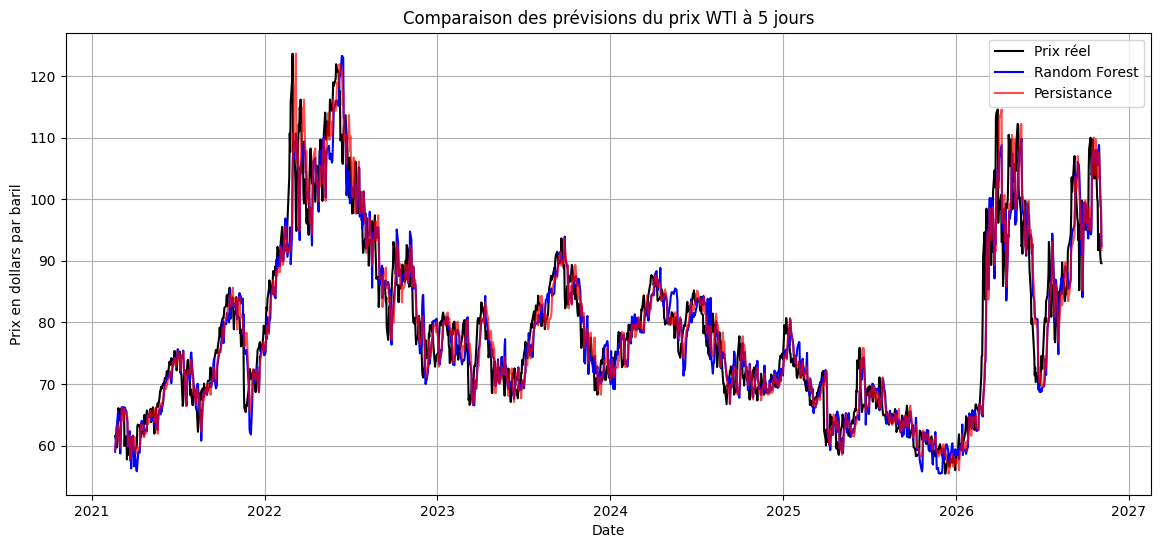

In [42]:
plt.figure(figsize=(14, 6))

plt.plot(
    y_test.index,
    y_test.values,
    label="Prix réel",
    color="black"
)

plt.plot(
    y_test.index,
    predictions_rf,
    label="Random Forest",
    color="blue"
)

plt.plot(
    y_test.index,
    predictions_persistance,
    label="Persistance",
    color="red",
    alpha=0.7
)

plt.title("Comparaison des prévisions du prix WTI à 5 jours")
plt.xlabel("Date")
plt.ylabel("Prix en dollars par baril")

plt.legend()
plt.grid(True)
plt.show()

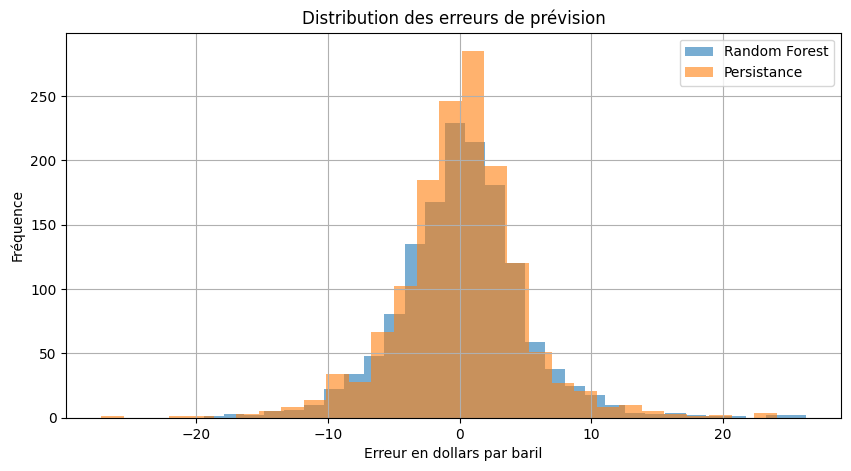

In [43]:
# Calcul des erreurs
erreurs_rf = y_test.values - predictions_rf

erreurs_p = y_test.values - predictions_persistance

# Distribution des erreurs
plt.figure(figsize=(10, 5))

plt.hist(
    erreurs_rf,
    bins=30,
    alpha=0.6,
    label="Random Forest"
)

plt.hist(
    erreurs_p,
    bins=30,
    alpha=0.6,
    label="Persistance"
)

plt.title("Distribution des erreurs de prévision")
plt.xlabel("Erreur en dollars par baril")
plt.ylabel("Fréquence")

plt.legend()
plt.grid(True)
plt.show()

,Variable,Importance
0,Prix_actuel,0.954351
7,Moyenne_5,0.031507
1,Prix_retard_1,0.006250
8,Moyenne_10,0.002775
12,Volatilite_20,0.000929
9,Moyenne_20,0.000858
5,Prix_retard_10,0.000652
6,Prix_retard_20,0.000615
11,Volatilite_10,0.000599
10,Volatilite_5,0.000426


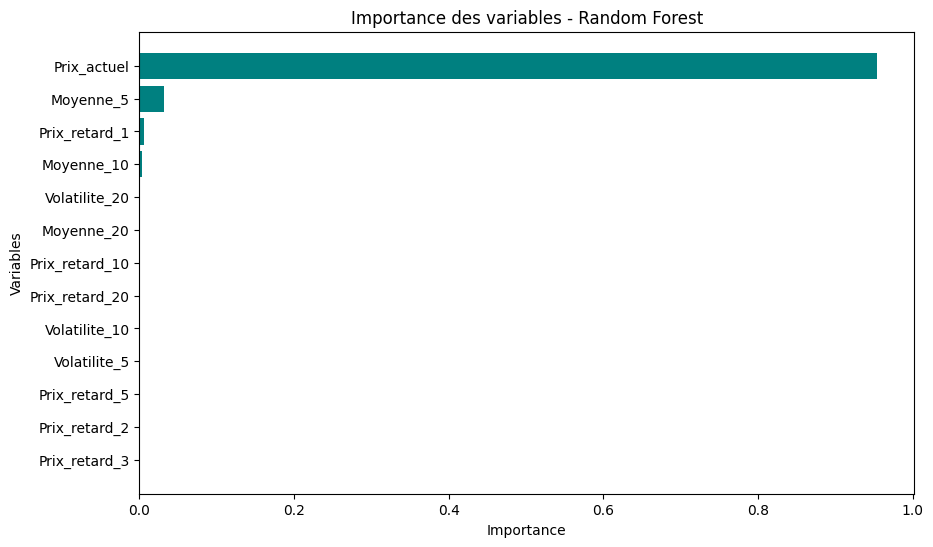

In [44]:
# Importance des variables
importance = pd.DataFrame({
    "Variable": X.columns,
    "Importance": modele_final.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

display(importance)

# Graphique
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Variable"],
    importance["Importance"],
    color="teal"
)

plt.title("Importance des variables - Random Forest")
plt.xlabel("Importance")
plt.ylabel("Variables")

plt.gca().invert_yaxis()
plt.show()

In [45]:
print("========== CONCLUSION DU PROJET ==========")

print("\nMAE Random Forest :", round(mae_rf, 4))
print("MAE Persistance :", round(mae_p, 4))

if mae_rf < mae_p:

    amelioration = (
        (mae_p - mae_rf) / mae_p
    ) * 100

    print("\nCONCLUSION :")

    print(
        "Le modèle Random Forest obtient une MAE "
        "inférieure à celle de la persistance."
    )

    print(
        f"La réduction de l'erreur absolue moyenne "
        f"est de {amelioration:.2f} %."
    )

    print(
        "Le modèle améliore donc la prévision sur "
        "la période de test étudiée."
    )

else:

    print("\nCONCLUSION :")

    print(
        "Le modèle Random Forest ne parvient pas "
        "à dépasser la méthode de persistance."
    )

    print(
        "La méthode naïve reste plus performante "
        "sur la période de test étudiée."
    )

print("\n==========================================")

========== CONCLUSION DU PROJET ==========

MAE Random Forest : 3.5721
MAE Persistance : 3.4249

CONCLUSION :
Le modèle Random Forest ne parvient pas à dépasser la méthode de persistance.
La méthode naïve reste plus performante sur la période de test étudiée.



In [46]:
# Tableau des prédictions
predictions = pd.DataFrame({
    "Prix_reel": y_test,
    "Prediction_RF": predictions_rf,
    "Prediction_Persistance": predictions_persistance
}, index=y_test.index)

# Export CSV
predictions.to_csv("predictions_WTI.csv")

# Export des métriques
resultats.to_csv("resultats_comparaison.csv", index=False)

print("Exportation terminée.")

Exportation terminée.
